# Pruebas de estrés inverso: el escenario más probable que rompe un umbral

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 04 y 05 de este tema (los escenarios, los satélites y el plan de capital)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué pregunta una prueba de estrés inverso (qué escenario plausible llevaría al banco a una falla predefinida) y el enunciado formal que usa el caso, un problema de distancia de Mahalanobis mínima;
- calcular el punto de falla del caso, la pila de capital mínimo legal chilena, y la pérdida que lo alcanza;
- escribir la pérdida del banco como función de dos factores macro con los satélites del motor, linealizarla y resolver el problema lineal en forma cerrada con `reverse_stress_linear`;
- resolver el problema real, no lineal, con `reverse_stress` desde varios puntos de partida, leer el escenario, su distancia y su plausibilidad, y comprobar la solución con `reverse_solution_check` del motor;
- decir cuán severo es el escenario que rompe al banco junto al de la Reserva Federal y a la crisis financiera global, y qué dice eso de la prueba de estrés.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.stress import capital, reverse, satellites
from riskvalidation.validation import stress as stress_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este cuaderno lee la variante de estrés inverso de **C18** (Banco Andino) y las piezas del escenario base con que se construye su pérdida.

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/reverse-stress.json` (el punto de falla, el espacio de factores, la solución versionada y sus cuatro puntos de partida), `baseline.json` (la trayectoria base, el capital en el punto de partida, el PPNR y las pérdidas esperadas base, la exposición de cada clase de préstamo, las tasas de retroproyección), `models-banco-andino.json` (los coeficientes de los satélites) y `fed-2026-severely-adverse.json` (las filas de severidad que comparan el escenario con la crisis financiera global).
- **Los umbrales de Banco Andino son convenciones.** El punto de falla, el CET1 en la pila de mínimo legal, es la formulación del caso y **no es texto regulatorio**; la parte de CET1 del Pilar 2 en esa pila es un supuesto declarado (0,0625 por ciento de los APR).

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

baseline = read_json("C18/baseline.json")["outputs"]
reverse_doc = read_json("C18/reverse-stress.json")
solution_doc = reverse_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
fed = read_json("C18/fed-2026-severely-adverse.json")["outputs"]
print("tipo:", solution_doc["kind"], "| modelo de pérdida:", solution_doc["loss_model"]["kind"], "| horneado con riskvalidation", reverse_doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

carpeta derived encontrada: sí
tipo: reverse | modelo de pérdida: nonlinear | horneado con riskvalidation 0.9.0 | instalado 0.9.0


## Método

### Paso 1: la pregunta y su enunciado formal

Una prueba de estrés parte de un escenario y pregunta qué pasa. Una **prueba de estrés inverso** parte de un resultado y pregunta qué escenarios lo causan: la guía europea EBA/GL/2018/04 la define como la que empieza con un resultado predefinido y explora los escenarios que podrían llevar a él (dossier 01, J.4). El enunciado formal es de Contraste, no texto regulatorio. Para una pérdida $L(x)$ como función de la **desviación $x$ de los factores macro respecto de su base**, con covarianza de factores $\Sigma$, el escenario más plausible que alcanza un umbral de pérdida $\ell$ es el de **mayor densidad** entre los que lo alcanzan, que para factores gaussianos (y elípticos) es el de **distancia de Mahalanobis mínima**:

$$x^{*} = \arg\min_x\; x^{\top}\Sigma^{-1}x \quad\text{sujeto a}\quad L(x) \ge \ell, \qquad d^{*} = \sqrt{x^{*\top}\Sigma^{-1}x^{*}}.$$

La atribución de este resultado elíptico a un artículo específico es NO VERIFICADA en el dossier (05, H.5); Glasserman, Kang y Kang (2015) estiman en cambio los escenarios más probables dadas pérdidas grandes por verosimilitud empírica, que el motor no implementa. Para una **pérdida lineal** $L(x) = g^{\top}x$ el problema tiene forma cerrada,

$$x^{*} = \frac{\Sigma g\,\ell}{g^{\top}\Sigma g}, \qquad d^{*} = \frac{\ell}{\sqrt{g^{\top}\Sigma g}},$$

y en otro caso se resuelve numéricamente. La **plausibilidad** de una solución es $P(\chi^2_k \ge d^{*2})$ con $k$ el número de factores: con qué frecuencia ocurre, bajo el modelo de factores, un escenario al menos así de lejos de la base.

La celda siguiente lee los rótulos de la solución versionada y el punto de falla, y recalcula el umbral de pérdida del caso: la **holgura del CET1 sobre la pila de mínimo legal chilena** en el punto de partida, en millones de CLP. La pila es $4,5\% + 2,5\% + \text{CCyB} + c_{\mathrm{DSIB}} + $ la parte de CET1 del Pilar 2, calculada por el motor (cuaderno 05).

In [3]:
# Leer el punto de falla, recalcular la pila con el motor y el umbral de pérdida: holgura del CET1 sobre la pila, en millones de CLP
failure = solution_doc["failure_point"]
start = baseline["capital_start"]
stack = capital.chilean_cet1_stack(failure["stack"]["c_ccyb"], failure["stack"]["c_dsib"], failure["stack"]["p2_cet1"]["value"])
threshold = (start["cet1_ratio"] - stack) * start["rwa_clp_m"]
print("rótulo del punto de falla:", failure["label"], "| horizonte (años):", failure["horizon_years"])
print("pila = 4.5% + 2.5% + CCyB + c_DSIB + parte de CET1 del Pilar 2:", round(stack, 6), "| versionada:", failure["stack"]["total"])
print("razón de CET1 en el punto de partida:", start["cet1_ratio"], "| APR:", round(start["rwa_clp_m"], 1))
print("holgura sobre la pila, millones de CLP:", round(threshold, 4), "| umbral de pérdida versionado:", round(solution_doc["solution"]["loss_threshold_clp_m"], 4))

rótulo del punto de falla: contraste-formulation-not-regulatory | horizonte (años): 3
pila = 4.5% + 2.5% + CCyB + c_DSIB + parte de CET1 del Pilar 2: 0.090625 | versionada: 0.09062500000000001
razón de CET1 en el punto de partida: 0.11 | APR: 7492853.0
holgura sobre la pila, millones de CLP: 145174.0275 | umbral de pérdida versionado: 145174.0275


### Paso 2: los factores

Los dos factores son el crecimiento del PIB real y la tasa de desempleo, los regresores de los satélites, y su comportamiento conjunto es la covarianza muestral de 1985 a 2019, la ventana de ajuste de los satélites. Un escenario aquí es una **desviación persistente** de ambos factores respecto de la trayectoria base de la Reserva Federal, la misma desviación en cada uno de los doce trimestres. El motor valida la covarianza antes de usarla (simétrica y definida positiva) y la rechaza en otro caso. La celda siguiente imprime la covarianza versionada, las desviaciones estándar y la correlación, y muestra a `reverse_stress_linear` rechazando una covarianza que no es definida positiva.

In [4]:
# Imprimir la covarianza de los factores, sus desviaciones estándar y la correlación, y mostrar el rechazo de una covarianza no definida positiva
space = solution_doc["factor_space"]
cov = np.array(space["covariance"])
sd = np.array([f["sd"] for f in space["factors"]])
print("factores:", [f["id"] for f in space["factors"]], "| ventana:", space["window"]["start"], "a", space["window"]["end"], "| rótulo:", space["label"])
print("covarianza:", np.round(cov, 4).tolist(), "| desviación estándar:", np.round(sd, 4), "| correlación:", round(float(cov[0, 1] / (sd[0] * sd[1])), 4))
try:
    reverse.reverse_stress_linear(np.array([1.0, 1.0]), np.array([[1.0, 2.0], [2.0, 1.0]]), 1.0)
except ValueError as err:
    # el motor escribe su mensaje en inglés; la tabla da su traducción y falla (KeyError) si el motor cambia el texto
    TRADUCCION = {"cov is not positive definite": "cov no es definida positiva"}
    print("una covarianza que no es definida positiva se rechaza:", TRADUCCION[str(err)])

factores: ['real_gdp_growth', 'unemployment_rate'] | ventana: 1985-03-31 a 2019-12-31 | rótulo: us-calibrated-adaptation
covarianza: [[5.2027, -0.5088], [-0.5088, 2.291]] | desviación estándar: [2.2809 1.5136] | correlación: -0.1474
una covarianza que no es definida positiva se rechaza: cov no es definida positiva


### Paso 3: la pérdida del banco como función de los factores

La pérdida del estrés inverso es la **pérdida a tres años del banco neta del PPNR acumulado base**: el CET1 del punto de partida más el PPNR acumulado menos las pérdidas acumuladas llega exactamente a la pila legal cuando esta pérdida neta iguala la holgura del paso 1. Se construye con piezas que el cuaderno ya usó. Para una desviación $x = (x_{\text{PIB}}, x_{\text{desempleo}})$:

1. desplazar en $x$ la trayectoria base del regresor de cada trimestre;
2. proyectar los cinco satélites (cuaderno 04) desde las últimas tasas realizadas;
3. mezclar los tipos de préstamo en las tres clases con los pesos del caso y tomar, para cada año, la exposición de cada clase por el promedio de sus cuatro tasas trimestrales;
4. sumar las pérdidas esperadas de mercado y operacional a tres años (3 veces la cifra anual) y restar el PPNR acumulado del escenario base.

Es el mismo cableado de la propia `loss_fn` del pipeline (`data-pipeline/pipeline/cases/c18/bake.py`), con todo estadístico proveniente de `project_scenario` del motor. La celda siguiente construye la función, comprueba que devuelve los números base versionados en $x = 0$ (una pérdida neta **negativa**: el PPNR base supera las pérdidas, así que no hace falta ningún estrés para estar en la base) y la evalúa en algunas desviaciones para mostrar su forma.

In [5]:
# Construir la pérdida neta como función de las dos desviaciones de factores con los satélites del motor y las piezas base versionadas
NAMES = ("real_gdp_growth", "unemployment_rate")
base_paths = {p["maps_to_regressor"]: p for p in baseline["scenario"]["paths"]}
base_path = np.column_stack([[row["value"] for row in base_paths[name]["transposed"]] for name in NAMES])
jump_off = np.array([[base_paths[name]["transposition"]["target"]["value"] for name in NAMES]])
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in baseline["backcast"]["per_loan_type"]}
classes = {k["banco_andino_class"]: k for k in baseline["satellites"]["banco_andino_classes"]}
other_expected = sum(m["el_clp_m"] for m in baseline["aggregation"]["marginals"] if m["risk"] in ("market", "operational"))
baseline_ppnr = sum(row["ppnr_clp_m"] for row in baseline["headline_cet1"]["ppnr"]["rows"])
fits = {}
for model in models["satellites"]:
    names = []
    for regressor in model["regressors"]:
        if regressor["name"] not in names:
            names.append(regressor["name"])
    fits[model["fed_loan_type"]] = satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"], n_obs=model["n_obs"],
        ar_order=model["ar_order"], regressor_names=tuple(names), lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in model["coefficients"]), estimates=tuple(c["estimate"] for c in model["coefficients"]),
        std_errors=tuple(c["std_error"] for c in model["coefficients"]), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])
last_link = {t: satellites.link(f.link, np.array([last_rate[t]])) for t, f in fits.items()}


def net_loss(x):
    # desplazar la trayectoria base, proyectar los satélites, mezclar en clases, sumar tres años de pérdida de crédito, agregar las otras pérdidas esperadas, menos el PPNR
    path = base_path + np.asarray(x, dtype=float)
    rates = {t: satellites.project_scenario(f, last_link[t], jump_off, path).rates for t, f in fits.items()}
    class_rate = {c: sum(w * rates[t] for w, t in zip(k["weights"], k["maps_from"])) for c, k in classes.items()}
    yearly = [float(sum(classes[c]["exposure_clp_m"] * float(np.mean(class_rate[c][4 * y: 4 * y + 4])) for c in ("commercial", "consumer", "mortgage"))) for y in range(3)]
    return float(sum(yearly)) + 3.0 * other_expected - baseline_ppnr


print("pérdidas esperadas restantes por año:", round(other_expected, 2), "| PPNR base a tres años:", round(baseline_ppnr, 1))
print("pérdida neta en la base (x = 0):", round(net_loss([0.0, 0.0]), 1), "| el umbral a alcanzar:", round(threshold, 1))
for x in ([-1.0, 0.0], [0.0, 3.0], [-2.0, 6.0], [-2.58, 12.42]):
    print(f"x = {x}: pérdida neta {net_loss(x):12,.1f}")

pérdidas esperadas restantes por año: 1187.54 | PPNR base a tres años: 441263.1
pérdida neta en la base (x = 0): -322940.3 | el umbral a alcanzar: 145174.0
x = [-1.0, 0.0]: pérdida neta   -321,627.4
x = [0.0, 3.0]: pérdida neta   -229,840.7
x = [-2.0, 6.0]: pérdida neta   -124,811.9
x = [-2.58, 12.42]: pérdida neta    145,240.8


### Paso 4: la forma cerrada sobre la pérdida linealizada

La pérdida no es lineal, por el enlace probit, pero en la base tiene un **gradiente** $g = \nabla L(0)$ en millones de CLP por punto porcentual de cada factor, que dan las diferencias finitas centrales. La aproximación lineal es $L(x) \approx L(0) + g^{\top}x$, así que la pérdida alcanza el umbral $\ell$ cuando $g^{\top}x = \ell - L(0)$, y `reverse_stress_linear(g, cov, ell - L(0))` devuelve el escenario en forma cerrada. El signo del gradiente dice la economía: negativo en el crecimiento del PIB (menos crecimiento, más pérdida) y positivo en el desempleo. La celda siguiente calcula el gradiente, la solución en forma cerrada y su distancia y plausibilidad, y luego **evalúa la pérdida no lineal verdadera en ese escenario**: si la pérdida fuera lineal sería igual al umbral exactamente.

In [6]:
# Gradiente de la pérdida neta en la base por diferencias centrales, la solución en forma cerrada del problema lineal y su pérdida verdadera
h = 1e-4
gradient = np.array([(net_loss(np.eye(2)[k] * h) - net_loss(-np.eye(2)[k] * h)) / (2 * h) for k in range(2)])
loss_at_zero = net_loss([0.0, 0.0])
linear = reverse.reverse_stress_linear(gradient, cov, threshold - loss_at_zero)
print("gradiente (millones de CLP por punto porcentual), crecimiento del PIB y desempleo:", np.round(gradient, 0))
print("solución lineal x* =", np.round(linear.x_star, 3), "| z* =", np.round(linear.z_star, 3), "| distancia:", round(linear.distance, 4), "| método:", linear.method)
print("pérdida linealizada en x*:", round(loss_at_zero + float(gradient @ linear.x_star), 1), "| pérdida verdadera en x*:", round(net_loss(linear.x_star), 1), "| umbral:", round(threshold, 1))
print("plausibilidad del escenario lineal, P(chi2_2 >= d^2):", reverse.plausibility(linear.distance, 2))

gradiente (millones de CLP por punto porcentual), crecimiento del PIB y desempleo: [-1055. 29244.]
solución lineal x* = [-4.776 15.835] | z* = [-2.094 10.462] | distancia: 10.4767 | método: closed-form-linear
pérdida linealizada en x*: 145174.0 | pérdida verdadera en x*: 317698.6 | umbral: 145174.0
plausibilidad del escenario lineal, P(chi2_2 >= d^2): 1.4639858300441684e-24


### Paso 5: el problema no lineal, desde varios puntos de partida

El problema verdadero es no lineal, así que `reverse_stress(loss_fn, cov, threshold, starts)` del motor minimiza $x^{\top}\Sigma^{-1}x$ sujeto a $L(x) \ge \ell$ con SLSQP desde cada punto de partida (gradientes por diferencias centrales y reinicios en caliente). **Una búsqueda local no prueba nada desde un solo punto**, así que se exigen al menos tres puntos y se devuelve la mejor solución convergida con el resultado de cada punto. Un punto converge cuando SLSQP tiene éxito y la pérdida está dentro de una tolerancia relativa del umbral. Los cuatro puntos del caso son puntos deterministas en el cuadrante adverso (el crecimiento cae, el desempleo sube), en múltiplos de las desviaciones estándar de los factores: $(-1, 5)$, $(-0,5; 7)$, $(-2, 8)$ y $(0, 9)$. La celda siguiente corre el solucionador, imprime cada punto y compara la solución, su distancia y su plausibilidad con las versionadas.

In [7]:
# Resolver el problema no lineal desde los cuatro puntos del caso y comparar la solución con la versionada
starts = [np.array([a * sd[0], b * sd[1]]) for a, b in ((-1.0, 5.0), (-0.5, 7.0), (-2.0, 8.0), (0.0, 9.0))]
best, each = reverse.reverse_stress(net_loss, cov, threshold, starts)
committed = solution_doc["solution"]
for k, (mine, theirs) in enumerate(zip(each, solution_doc["starts"]), start=1):
    print(f"punto {k}: convergió {sino(mine.converged):5s} distancia {mine.distance:.12f} | versionado: convergió {sino(theirs['converged']):5s} distancia {theirs['distance']:.12f}")
print("solución x* =", np.round(best.x_star, 4), "| versionada:", np.round(committed["x_star"], 4))
print("z* =", np.round(best.z_star, 4), "| distancia:", round(best.distance, 6), "| versionada:", round(committed["mahalanobis_distance"], 6), "| método:", best.method)
print("pérdida en x*:", round(best.loss_at_x, 3), "| umbral:", round(threshold, 3), "| brecha relativa:", abs(best.loss_at_x - threshold) / threshold)
print("plausibilidad P(chi2_2 >= d^2):", reverse.plausibility(best.distance, 2), "| versionada:", committed["plausibility"]["tail_probability"])
print("distancia de la solución lineal:", round(linear.distance, 4), "| de la no lineal:", round(best.distance, 4))

punto 1: convergió sí    distancia 8.205018940205 | versionado: convergió sí    distancia 8.205018940205
punto 2: convergió no    distancia 8.205018940204 | versionado: convergió no    distancia 8.205018940204
punto 3: convergió sí    distancia 8.205018940205 | versionado: convergió sí    distancia 8.205018940205
punto 4: convergió sí    distancia 8.205018940205 | versionado: convergió sí    distancia 8.205018940205
solución x* = [-2.5805 12.4186] | versionada: [-2.5805 12.4186]
z* = [-1.1313  8.2046] | distancia: 8.205019 | versionada: 8.205019 | método: scipy-optimize
pérdida en x*: 145174.027 | umbral: 145174.027 | brecha relativa: 4.2300322816103484e-14
plausibilidad P(chi2_2 >= d^2): 2.4051409053671115e-15 | versionada: 2.4051409053671115e-15
distancia de la solución lineal: 10.4767 | de la no lineal: 8.205


### Paso 6: comprobar la solución

Un optimizador numérico puede detenerse en un punto que no es solución, así que el motor trae una verificación, `reverse_solution_check(loss_at_x, threshold, distance, start_distances)`: **roja** cuando la pérdida en la solución no alcanza el umbral por más de una tolerancia, o cuando algún punto de partida encontró un punto más cercano que la solución; **verde** en otro caso; `not_evaluated` con menos de tres puntos. Su métrica es el punto más cercano sobre la distancia de la solución, menos 1 (cero o positiva cuando ningún punto es más cercano). La celda siguiente la corre sobre la solución y las distancias de los puntos convergidos, compara con la fila versionada y luego la corre sobre una falla **plantada**, una distancia de partida 10 por ciento bajo la de la solución, para verla ponerse roja.

In [8]:
# Correr la verificación de la solución del motor sobre la solución real y sobre una falla plantada, y comparar con la fila de prueba versionada
converged = [s.distance for s in each if s.converged]
check = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, converged)
committed_row = next(t for t in reverse_doc["tests"] if t["test_id"] == "stress.reverse_solution_check")
print("puntos convergidos:", len(converged), "| luz:", check.light.value, "| estadístico:", check.statistic, "| métrica:", check.metric)
print("fila versionada  : luz", committed_row["light"], "| estadístico:", committed_row["statistic"], "| métrica:", committed_row["metric"])
bad = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, converged[:-1] + [0.9 * best.distance])
print("plantada: un punto al 90 por ciento de la distancia: luz:", bad.light.value, "| punto más cercano encontrado:", sino(bad.extras["closer_start"]))
few = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, converged[:2])
# el motor escribe su nota en inglés; la tabla da su traducción y falla (KeyError) si el motor cambia el texto
TRADUCCION = {"not evaluated: 2 starts: at least three are required": "no evaluada: 2 puntos de partida: se requieren al menos tres"}
print("solo dos puntos: luz:", few.light.value, "|", TRADUCCION[few.notes])

puntos convergidos: 3 | luz: green | estadístico: 4.2300322816103484e-14 | métrica: 0.0
fila versionada  : luz green | estadístico: 4.2300322816103484e-14 | métrica: 0.0
plantada: un punto al 90 por ciento de la distancia: luz: red | punto más cercano encontrado: sí
solo dos puntos: luz: not_evaluated | no evaluada: 2 puntos de partida: se requieren al menos tres


### Paso 7: ¿cuán severo es el escenario que rompe al banco?

La solución es una desviación de ambos factores, **sostenida por doce trimestres**, respecto de la base. Dos puntos de referencia le dan escala. El escenario severamente adverso de la Reserva Federal llega a un máximo 5,5 puntos sobre su desempleo inicial, que la fila de severidad versionada del caso compara con los 5,1 puntos de la crisis financiera global (2008 T1 a 2009 T4). La celda siguiente lee esas filas, expresa la solución en desviaciones estándar de cada factor e imprime cuántas veces mayor es la desviación de desempleo de la solución que los máximos de la Reserva Federal y de la crisis. Imprime también lo que dice el modelo de factores de cuán rara es la solución: la plausibilidad del paso 5 y el número equivalente de desviaciones estándar de una sola variable normal con la misma probabilidad de cola.

In [9]:
# Comparar la solución con el escenario de la Reserva Federal y con la crisis financiera global en el factor desempleo
severity = {row["maps_to_regressor"]: row for row in fed["severity"]["rows"]}
unemployment = severity["unemployment_rate"]
x_gdp, x_unemployment = best.x_star
print(f"solución: crecimiento del PIB {x_gdp:+.2f} puntos, desempleo {x_unemployment:+.2f} puntos, sostenidos por 12 trimestres | en desviaciones estándar: {np.round(best.z_star, 2)}")
print(f"desviación máxima del desempleo: severamente adverso de la Reserva Federal {unemployment['path_peak_deviation']:.1f} | crisis financiera global {unemployment['history_peak_deviation']:.1f}")
print(f"la desviación de desempleo de la solución es {x_unemployment / unemployment['path_peak_deviation']:.1f} veces el máximo de la Reserva Federal y {x_unemployment / unemployment['history_peak_deviation']:.1f} veces el máximo de la crisis")
tail = reverse.plausibility(best.distance, 2)
print("probabilidad de cola bajo el modelo de factores:", tail, "| cuantil normal unilateral con esa probabilidad de cola:", round(float(stats.norm.isf(tail)), 2), "desviaciones estándar")

solución: crecimiento del PIB -2.58 puntos, desempleo +12.42 puntos, sostenidos por 12 trimestres | en desviaciones estándar: [-1.13  8.2 ]
desviación máxima del desempleo: severamente adverso de la Reserva Federal 5.5 | crisis financiera global 5.1
la desviación de desempleo de la solución es 2.3 veces el máximo de la Reserva Federal y 2.4 veces el máximo de la crisis
probabilidad de cola bajo el modelo de factores: 2.4051409053671115e-15 | cuantil normal unilateral con esa probabilidad de cola: 7.83 desviaciones estándar


## Resultados

El gráfico dibuja el plano de factores: las elipses de distancia de Mahalanobis 2, 4, 6 y la de la solución (8,2), el contorno donde la pérdida neta verdadera iguala el umbral, la base en el origen, la solución versionada donde el contorno toca la última elipse y la solución en forma cerrada de la pérdida linealizada. La solución es el punto del contorno de pérdida más cercano a la base en distancia de Mahalanobis, que es donde el contorno es **tangente** a una elipse.

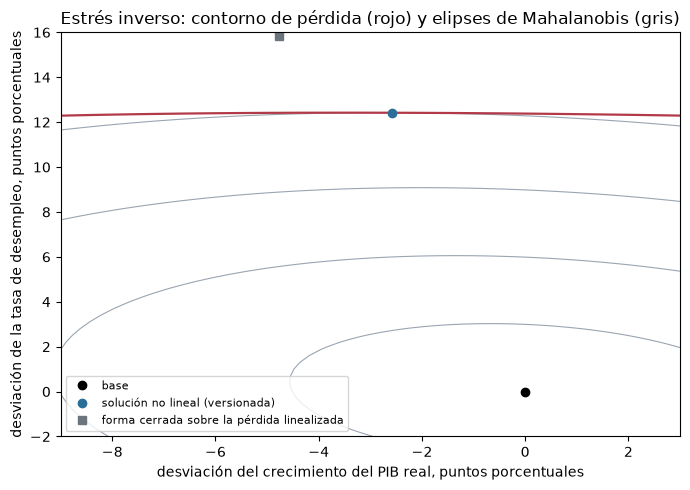

In [10]:
# Dibujar las elipses de Mahalanobis, el contorno donde la pérdida neta iguala el umbral y las dos soluciones
gx, gy = np.linspace(-9, 3, 61), np.linspace(-2, 16, 61)
grid_loss = np.array([[net_loss([a, b]) for a in gx] for b in gy])
precision = np.linalg.inv(cov)
distance_grid = np.sqrt(precision[0, 0] * gx[None, :] ** 2 + 2 * precision[0, 1] * gx[None, :] * gy[:, None] + precision[1, 1] * gy[:, None] ** 2)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(gx, gy, distance_grid, levels=[2, 4, 6, round(best.distance, 3)], colors="#9aa5b1", linewidths=0.8)
ax.contour(gx, gy, grid_loss, levels=[threshold], colors="#b23a48", linewidths=1.6)
ax.plot([0], [0], "ko", label="base")
ax.plot(*best.x_star, "o", color="#2a6f97", label="solución no lineal (versionada)")
ax.plot(*linear.x_star, "s", color="#6c757d", label="forma cerrada sobre la pérdida linealizada")
ax.set_xlabel("desviación del crecimiento del PIB real, puntos porcentuales")
ax.set_ylabel("desviación de la tasa de desempleo, puntos porcentuales")
ax.set_title("Estrés inverso: contorno de pérdida (rojo) y elipses de Mahalanobis (gris)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

- **El punto de falla es una razón de CET1 de 9,0625 por ciento** (la pila legal), 1,9375 puntos de los APR bajo el 11,0 por ciento de partida: un umbral de pérdida de **CLP 145.174,0 millones**, igual al versionado. Los dos factores tienen desviaciones estándar de 2,28 (crecimiento del PIB) y 1,51 (desempleo) puntos y una correlación de -0,147; el motor rechaza una covarianza que no es definida positiva.
- **En la base la pérdida neta es -322.940**: el PPNR base a tres años (441.263) supera las pérdidas, así que el banco está a CLP 468.114 millones de pérdida neta del punto de falla y "sin estrés" no es la pregunta aquí.
- **Los satélites hacen del desempleo el factor dominante.** El gradiente de la pérdida neta en la base es -1.055 millones de CLP por punto de crecimiento del PIB y +29.244 por punto de desempleo, unas 28 veces mayor.
- **El problema linealizado se resuelve en forma cerrada** (`x*` = -4,78 puntos de crecimiento y +15,84 de desempleo, distancia 10,48), pero la pérdida verdadera en ese escenario es 317.699, 2,2 veces el umbral: el enlace probit es convexo, así que la forma cerrada lineal se pasa y el escenario verdadero está más cerca.
- **La solución no lineal es una desviación persistente de -2,58 puntos de crecimiento del PIB y +12,42 de desempleo** ($z^* = (-1,13; 8,20)$, distancia 8,205019), igual a la versionada al dígito, con una pérdida que no alcanza el umbral por 4,2e-14 en términos relativos. Tres de los cuatro puntos de partida convergieron, como en el documento versionado, y el cuarto se detuvo en la misma distancia a doce dígitos. La plausibilidad es 2,4e-15, equivalente a 7,8 desviaciones estándar de una sola variable normal.
- **La verificación de la solución es verde** con tres puntos convergidos (estadístico 4,2e-14, métrica 0, la fila versionada), se pone roja al plantar un punto al 90 por ciento de la distancia de la solución y devuelve `not_evaluated` con solo dos puntos.
- **El escenario que rompe al banco es 2,3 veces el máximo de desempleo del escenario severamente adverso de la Reserva Federal (5,5 puntos) y 2,4 veces el de la crisis financiera global (5,1 puntos)**, sostenido por tres años.

Lo que este cuaderno no muestra: la pérdida es un piso (el riesgo de mercado y el operacional llevan solo su pérdida esperada) y su PPNR es una fila rotulada sobre razones supuestas, así que la distancia es una propiedad de este modelo y sus insumos; los satélites sobre los que corre fallan su propia retroproyección (cuaderno 07), lo cual es una razón para leer la distancia como una afirmación sobre los satélites; y el estimador de verosimilitud empírica de Glasserman, Kang y Kang no está en el motor.

## Resumen

- Una prueba de estrés inverso parte de la falla y pide el escenario más plausible que la alcanza; el enunciado formal del caso es el escenario de distancia de Mahalanobis mínima sobre la superficie de pérdida, formulación de Contraste y no texto regulatorio.
- El punto de falla es el CET1 en la pila de mínimo legal chilena al final de los tres años; el umbral es la holgura del CET1 sobre ella, y la pérdida es la pérdida a tres años neta del PPNR base.
- Para una pérdida lineal la solución es de forma cerrada; la pérdida del caso es no lineal por el enlace probit, así que el motor la resuelve numéricamente desde varios puntos y una verificación rechaza una solución que no alcanza el umbral o que tiene un punto más cercano.
- El escenario que rompe al banco está muy más allá de todo estrés del registro: necesita un desplazamiento persistente del desempleo de más del doble del máximo severamente adverso de la Reserva Federal y una plausibilidad cercana a $10^{-15}$ bajo el modelo de factores, lo que dice más de la resiliencia del banco en este caso sintético, y de lo que omiten sus insumos, que de la economía.

**Qué probar a continuación.** Cambia la parte de CET1 del Pilar 2 en la pila del paso 1 y mira moverse el umbral y la distancia; luego sigue con el cuaderno 07, que valida los componentes de agregación y estrés con las baterías de pruebas del motor.

## Referencias

- Glasserman, P., Kang, C. y Kang, W. (2015), Stress scenario selection by empirical likelihood, Quantitative Finance 15(1). https://doi.org/10.1080/14697688.2014.926019
- Dossiers 01 (J.4, la formulación del estrés inverso y EBA/GL/2018/04) y 05 (H.5, pruebas de estrés inverso) de la investigación persistida de Contraste, resumidos en la base de investigación del SDD.
- Este repositorio: `docs/contracts/engine/stress-api.md` (las funciones de estrés inverso) y `docs/design/features/c18/requirements.md` (CT-1815 y CT-1822).